In [1]:
try:
    import sktime
    import pmdarima
    import prophet
    import yfinance
except ImportError as e:
    print(f"Error importing modules: {e}")
    !pip install sktime
    !pip install pmdarima
    !pip install prophet
    !pip install yfinance
    import sktime
    import pmdarima
    import prophet
    import yfinance

from sktime.registry import all_estimators
import pandas as pd
from sktime.datasets import load_airline
from sktime.forecasting.base import ForecastingHorizon
from sktime.forecasting.model_selection import temporal_train_test_split
from sktime.performance_metrics.forecasting import mean_absolute_percentage_error, mean_absolute_percentage_error, mean_squared_error
from sktime.utils.plotting import plot_series

from matplotlib import pyplot as plt
import seaborn as sns
from sktime.forecasting.exp_smoothing import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from sktime.forecasting.compose import TransformedTargetForecaster

Importing plotly failed. Interactive plots will not work.


# Time Series Forecasting

We can revisit time series forecasting breifly and look at a few techniques to generate forecasts. 

### Components of Time Series

We can break down a time series into components:
<ul>
<li> Trend - the overall direction of the series. 
<li> Seasonality - the periodicity of the series. 
<li> Noise/Irregularity - the random variation of the series.
<li> Cyclic - the non-periodic variation of the series.
</ul>

![Time Series Parts](images/time_series_parts.jpg "Time Series Parts")

These all impact forecasting when dealing with time series data. We need to know the general trend, are we going up or down? We need to know about seasonality, is there a pattern that repeats itself? We need to know about noise, is there a lot of random variation? We need to know about cyclic, is there a pattern that repeats itself but not on a regular basis? All of the time series techniques below are variations of extracting these components to make reliable predictions. We won't go extremely deep into time series forecasting, it is a large topic and has quite a few differences from the other work that we are doing. The aim here is to give an overview of some of the tools we can use to approach time series data, and build a bit of a foundation for further exploration should you encounter these challenges. 

## Time Series Forecasting with SKtime

SKtime provides a familiar interface to time series functionality. 

### Common Lingo

<ul>
<li> forecaster = model
<li> ForecasterHorizon = what to create predictions for
</ul>

#### Load Airline Data

Our ariline data here measures the number of passengers per month from 1949 to 1960. We will use this data to predict the number of passengers looking forward. 

(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Number of airline passengers'>)

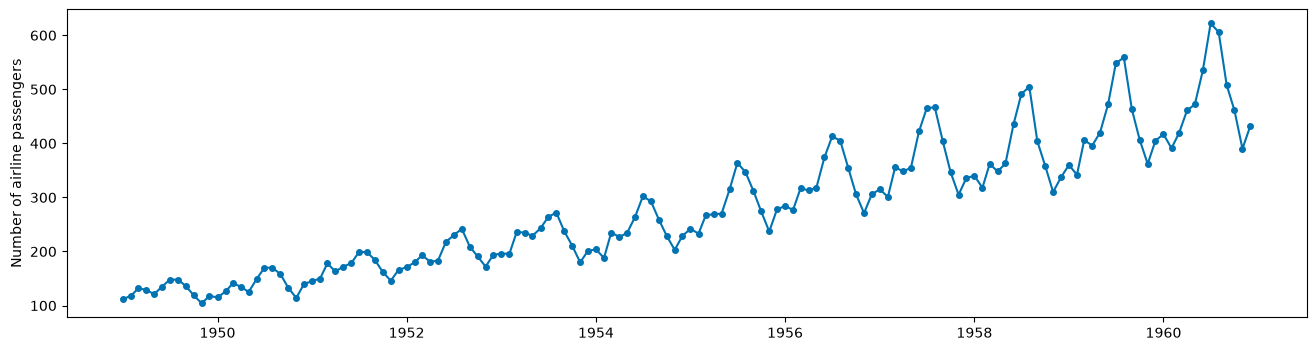

In [2]:
y = load_airline()
plot_series(y)

### Show Decomposition

We can use the seasonal_decompose function to break down the time series into its components. This will help us visualize the trend, seasonality, and noise in the data.

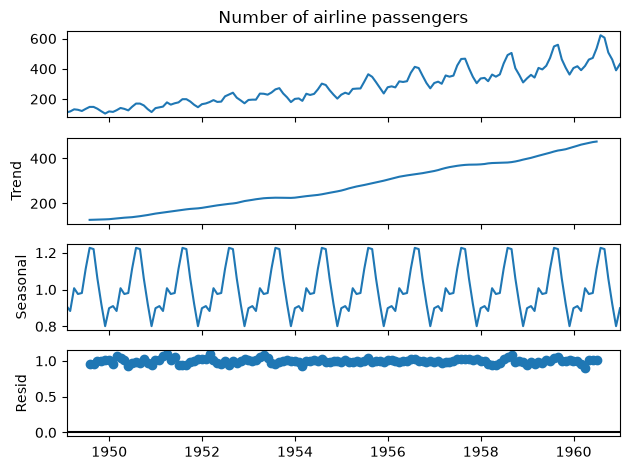

In [3]:
# Ensure the index of y is a DatetimeIndex
# This was error driven - I got an error, looked that up, and implmented this little correction. 
y_decomp = y.copy()
y_decomp.index = pd.date_range(start="1949-01", periods=len(y), freq="ME")

decomp_y = seasonal_decompose(y_decomp, model="multiplicative", period=12)
decomp_y.plot()
plt.show()

## Train-Test Split

Since time series runs sequentially, the train-test split for error calcualtions is normally just chopping off the last part of the sequence and use that to test. Sktime provides a dedicated function to do so. You'll commonly see array notation to slice before/after as well. 

Here we take the final 36 months for testing. We also make a forecast horizion, this one is set to be the months of the test data, since we are evaluating accuracy. 

In [4]:
y_train, y_test = temporal_train_test_split(y, test_size=36)
fh = ForecastingHorizon(y_test.index, is_relative=False)

## Exponential Smoothing. 

We can guess that the period is 12 months since it looks like a yearly pattern. We can also try the trend being additive and the seasonality being multiplicitive. We looked at exponential smoothing a little bit back in stats when we introduced residuals and error. In short, the exponential smoothing model is a smarter weighted average, with some wrinkles to account for trend and seasonality. These exponential smoothing models are a good starting point, and probably the most simple type of forecasting we can perform. 

### Additive or Multiplicitive

One thing we need to consider is if the trend and seasonality are additive or multiplicitive, or how it changes over time. Additive means that the trend and seasonality are added to the base value, multiplicitive means that the trend and seasonality are multiplied by the base value. This difference is important because it changes how we calculate the forecast, it is probably more easy to understand by looking at it visually. Rule of thumb: if the difference is changing over time -> multiplicitive, if it is constant -> additive. 

![Additive or Multiplicitive](images/add_mult.gif "Additive or Multiplicitive")

Here the size of the seasonal swings seems to be getting larger, so that is multiplicitive. The trend seems to be a constant increase, so additive. We can see how to test these later - it is not always obvious. 

For the trend we have the same question, is it additive or multiplicitive? We can see that the trend is increasing at a linear looking rate, so it is probably additive. Multiplicitive trends would follow the same pattern, the rate of increase would be increasing, so we'd see a general curve to the data. 

These factors act to "account for" the trend and seasonality swings in our data, effectively adapting the weighting of values used in the weighted average to capture both the general increase in value from the trend, and the up and down swings from the seasonality.

np.float64(0.050687597458295666)

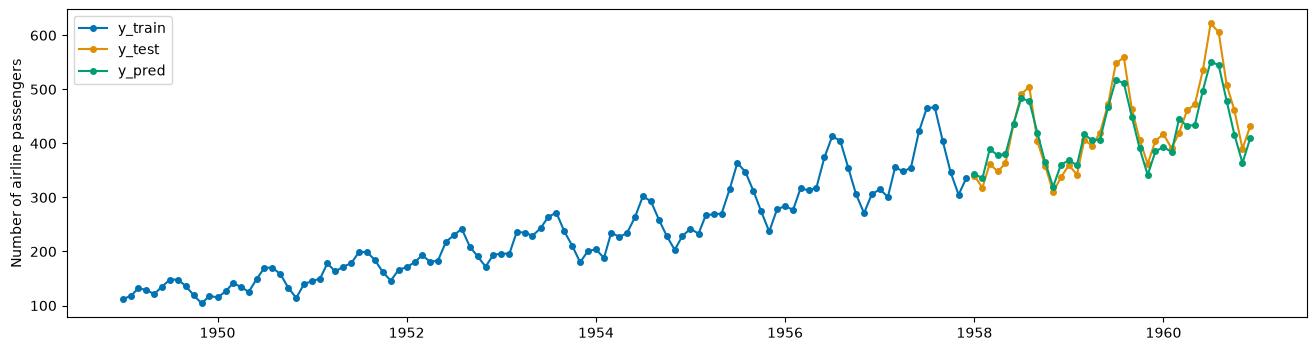

In [5]:
forecaster = ExponentialSmoothing(trend="add", seasonal="mul", sp=12)

forecaster.fit(y_train)
y_pred = forecaster.predict(fh)
plot_series(y_train, y_test, y_pred, labels=["y_train", "y_test", "y_pred"])
mean_absolute_percentage_error(y_test, y_pred)

### Residual Analysis

We can look at the residuals of our model to see how well it is performing. We want the residuals to be randomly scattered, we don't want them to have a pattern to them.  If the residuals are not randomly scattered, then we have not captured all of the information in the data, and our model is not performing well. Ideally, we should also see them centered around zero, meaning our model isn't consistently over or under predicting.

I'll plot the residuals both over time and compared to the values. The try/except bit is to accommodate if the data is properly indexed with timestamps or not. 

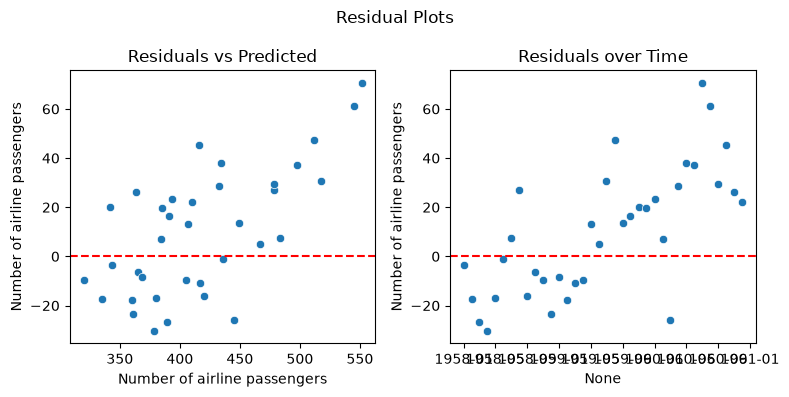

In [6]:
# Plot residuals
def residual_plot(y_test, y_pred):
    residuals = y_test - y_pred
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    sns.scatterplot(x=y_pred, y=residuals, ax=ax[0])
    try:
        sns.scatterplot(x=residuals.index.to_timestamp(), y=residuals, ax=ax[1])
    except:
        sns.scatterplot(x=residuals.index, y=residuals, ax=ax[1])
    plt.suptitle("Residual Plots")
    plt.axes(ax[0]).set_title("Residuals vs Predicted")
    plt.axhline(0, color='red', linestyle='--')
    plt.axes(ax[1]).set_title("Residuals over Time")
    plt.axhline(0, color='red', linestyle='--')
    plt.tight_layout()

residual_plot(y_test, y_pred)

Results - it looks like our model was pretty good. What if we want to make predictions into the future? We need to modify the forecasting horizion to, well, look into the horizon, then it is pretty similar. We can give the month indicies for the future months, as well as an argument "is_relative" that will tell sktiem to pick up at the end. 

We can also retrain the model to use all the data, since we are done evaluating the model here. 

(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Number of airline passengers'>)

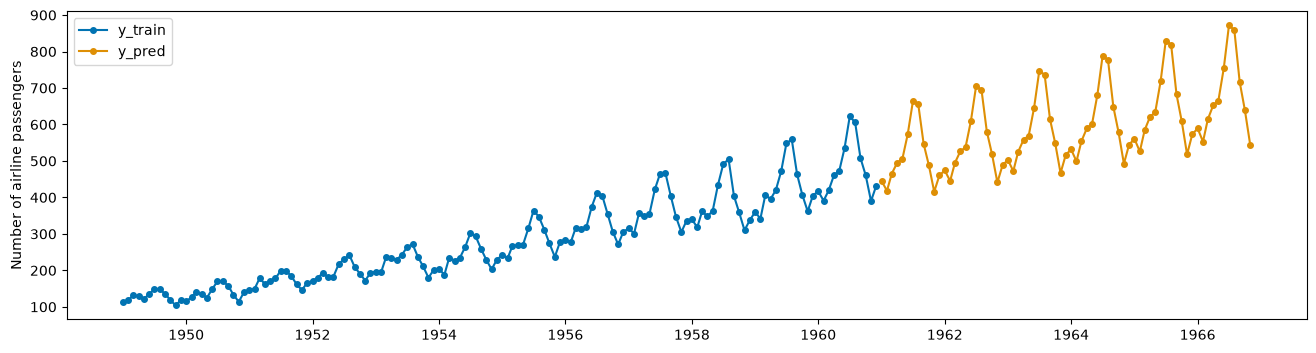

In [7]:
# Next 6 years
dates_range = list(range(1, 72))
fh_long = ForecastingHorizon(values=dates_range, is_relative=True)
forecaster.fit(y)
y_pred = forecaster.predict(fh_long)
plot_series(y, y_pred, labels=["y_train", "y_pred"])

#### Results

Based on the pattern that we can see in our data, our projections look pretty good. If the pattern keeps up into the "future", we can expect our model's predictions to be accurate. Since we are projecting into the future, we can expect that our confidence in our predictions will decrease the farther out we go into the future. For patterns that are relatively stable like birth rates, our models will likely be quite good; for patterns that have many random variations or outside "shocks", like stock prices, our confidence in our predictions will be lower. 

## AutoRegressive Integrated Moving Average - ARIMA

<b>Note: we will largely deemphasize the process for finding the optimal parameters for the model, as it is a bit involved, and not super relevant to the other work we'll be doing. This part is really more of an exploration, we can rely on the automated tools to find the optimal parameters for us.</b>

A famous and widely used forecasting method for time-series prediction is the AutoRegressive Integrated Moving Average (ARIMA) model. ARIMA models are capable of capturing a suite of different standard temporal structures in time-series data.

ARIMA relies on a few specific parts:
<ul>
<li> AR: < Auto Regressive > means that the model uses the dependent relationship between an observation and some predefined number of lagged observations (also known as “time lag” or “lag”).
<li> I:< Integrated > means that the model employs differencing of raw observations (e.g. it subtracts an observation from an observation at the previous time step) in order to make the time-series stationary.
<li> MA: < Moving Average > means that the model exploits the relationship between the residual error and the observations.
</ul>

There a few model parameters that we need to supply as well, the standard ARIMA models expect as input parameters 3 arguments i.e. p,d,q.
<ul>
<li> p is the number of lag observations.
<li> d is the degree of differencing.
<li> q is the size/width of the moving average window.
</ul>

We can try a similar approach to the predictions we made with exponential smoothing above with an ARIMA model. There is a more detailed explaination here, we don't need to get too bogged down in the details though: https://www.machinelearningplus.com/time-series/arima-model-time-series-forecasting-python/ there's also a workbook with good explanations and examples here: https://www.kaggle.com/code/iamleonie/time-series-interpreting-acf-and-pacf 

#### ARIMA from Scratch

The ARIMA model is a bit more complex than the exponential smoothing model, in particular this explortation for the optimal parameters is a bit more involved. Below, we have a bit more efficient method of finding the optimal parameters, and in practice we can rely on that (and similar approaches) to find the optimal parameters for a model. This next part if mostly for illustration purposes, but if it isn't super logical to you, we are safe to skip the details, as long as the concepts make sense. This parameter finding exercise is  kind of an odd process, so we don't want to get too bogged down in the details if they are not clear. 

In [8]:
from sktime.forecasting.arima import ARIMA

#### AD Fuller Test for D Term

Our first goal here is to make the time series "stationary", or remove the trend and seasonality. We can do this by differencing the data, or subtracting it from a previous value. The number of .diff()s in the code is the number of differences that we are introducing. We can use the Augmented Dickey-Fuller test to determine the number of differences we need to make the data stationary. The ADF test aims to reject the null hypothesis that the given time-series data is non-stationary. It calculates the p-value and compares it with a threshold value or significance level of 0.05. If the p-value is less than this level, then the data is stationary; else, the differencing order is incremented by one. Or in English, we are doing a hypothesis test of "is the data stationary", with a null hypothesis of "the data is non-stationary". If the p-value is less than 0.05, we have a good dataset, and we set the d value to this - the smallest number of diffs that makes the data stationary.

Visually, we want the data to be "flat" and not have a trend.

ADF Statistic: -2.829267
p-value: 0.054213


(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Number of airline passengers'>)

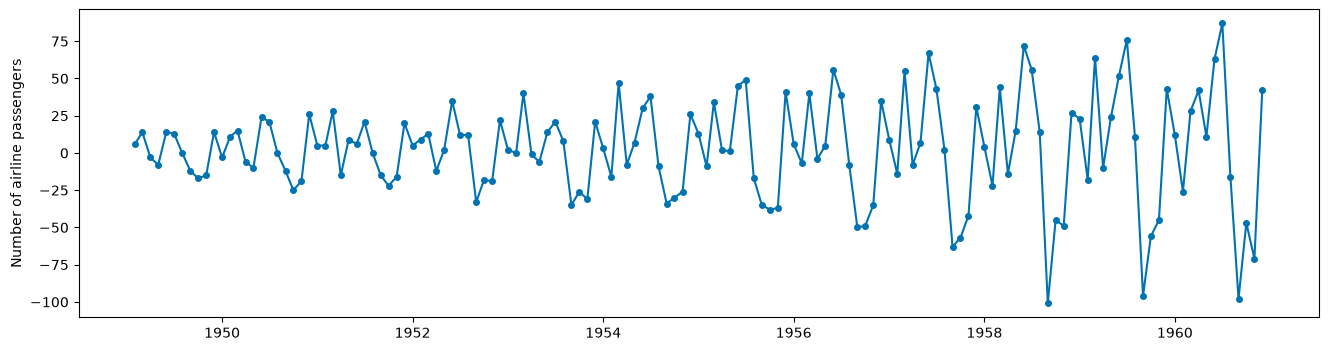

In [9]:
from statsmodels.tsa.stattools import adfuller
result = adfuller(y.diff().dropna(), result_object=True)
print('ADF Statistic: %f' % result.statistic)
print('p-value: %f' % result.pvalue)
plot_series(y.diff())

ADF Statistic: -16.384232
p-value: 0.000000
Series is stationary


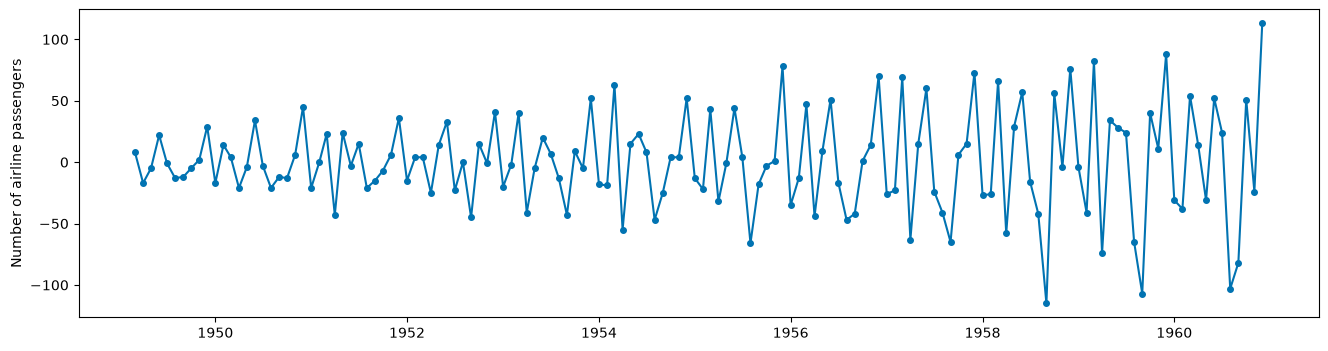

In [10]:
# Try second order differencing
result = adfuller(y.diff().diff().dropna(), result_object=True)
print('ADF Statistic: %f' % result.statistic)
print('p-value: %f' % result.pvalue)
if result.pvalue < 0.05:
    print('Series is stationary')
else:
    print('Series is not stationary')

plot_series(y.diff().diff())

d_arima = 2

## Autocorrelation and Partial Autocorrelation for MA and AR. 

Determining p and q is a little more haphazard. Below is a processes to look for them with the ACF and PACF charts. In short, we can look for a starting point, then potentially adjust. We will have a solution for this soon...

<b>Process:</b>
<ol>
<li>If the PACF of the differenced series shows a sharp cut off and/or the lag1 autocorrelation is positive (this indicates an ‘under- differenced’ series) while the ACF decays more slowly , then consider adding an AR term to the model. The number of AR terms will depend on the lag at which PACF cuts off.
<li>If the ACF of the differenced series shows a sharp cut off and/or the lag1 autocorrelation is negative (this indicates an ‘over- differenced’ series) while the PACF decays more slowly , then consider adding MA term to the model. Here, the autocorrelation pattern is explained more by adding the MA terms. The number of MA terms will depend on the lag at which ACF cuts off.
<li>An AR term is associated with under-differencing or positive auto correlation at lag 1while an MA term is associated with over-differencing or negative auto correlation at lag 1.
</ol>

In [11]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

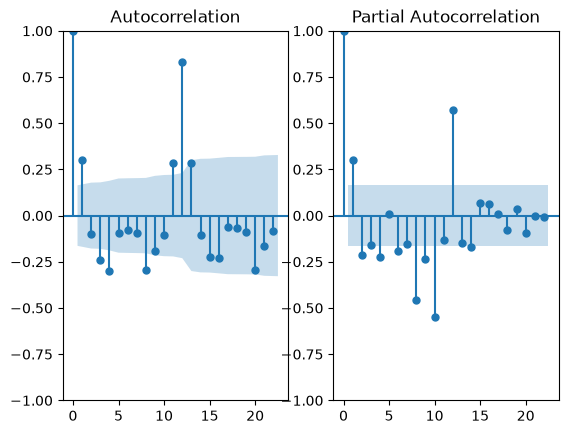

In [12]:
# ACF/PACF plot of 1st differenced series
fig, axes = plt.subplots(1, 2)
plot_acf(y.diff().dropna(), ax=axes[0])
plot_pacf(y.diff().dropna(), ax=axes[1])

plt.show()

In [13]:
p_arima = 1
q_arima = 1

We can try:
<ul>
<li> AR (p) - 1
<li> I (d) - 1
<li> MA (q) - 1
</ul>

### Check Model Accuracy

We'll make a model with the parameters that we determined above, make some test predictions, and calculate the error.

#### Why So Straight?

Our model probably looks a bit "straight" compared to the actual data. This is because we are using a simple ARIMA model, and it is not capturing the seasonality in the data. Remember the decomposition? We captured part of that, the trend, but we ignored another part, the seasonality. We can use a SARIMA, or Seasonal ARIMA model, to try to do better. 

In [14]:
seasonal_decompose(y_decomp, model="multiplicative", period=12)

np.float64(0.1205985418888643)

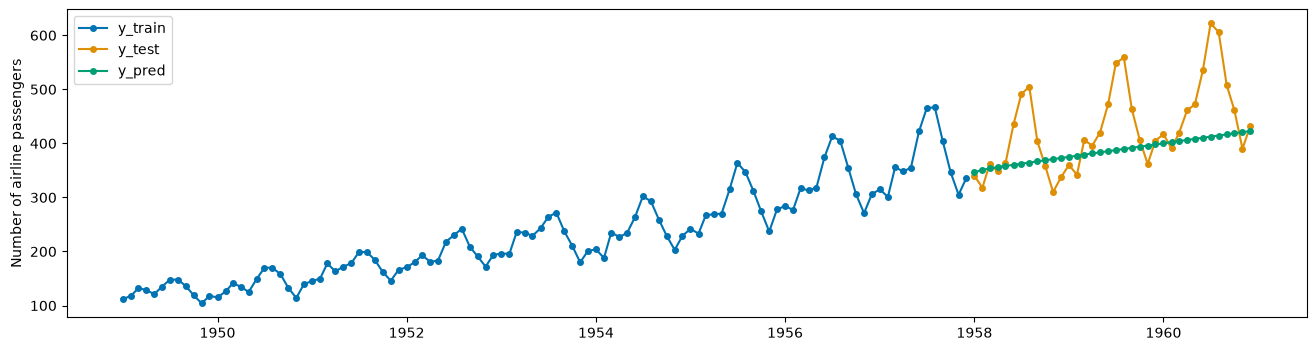

In [15]:
forecaster = ARIMA(order=( p_arima, d_arima, q_arima))

forecaster.fit(y_train)
y_pred = forecaster.predict(fh)
plot_series(y_train, y_test, y_pred, labels=["y_train", "y_test", "y_pred"])
mean_absolute_percentage_error(y_test, y_pred)

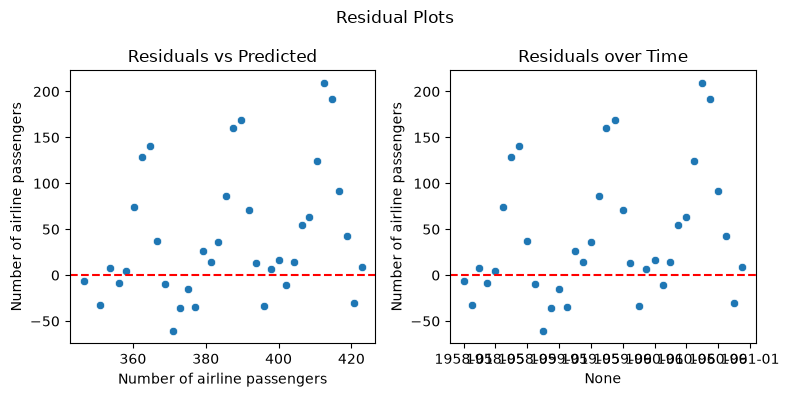

In [16]:
residual_plot(y_test, y_pred)

#### Predict Into Future

If we are happy with our model, which we aren't, we can retrain it on all the data and make predictions into the future.

(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Number of airline passengers'>)

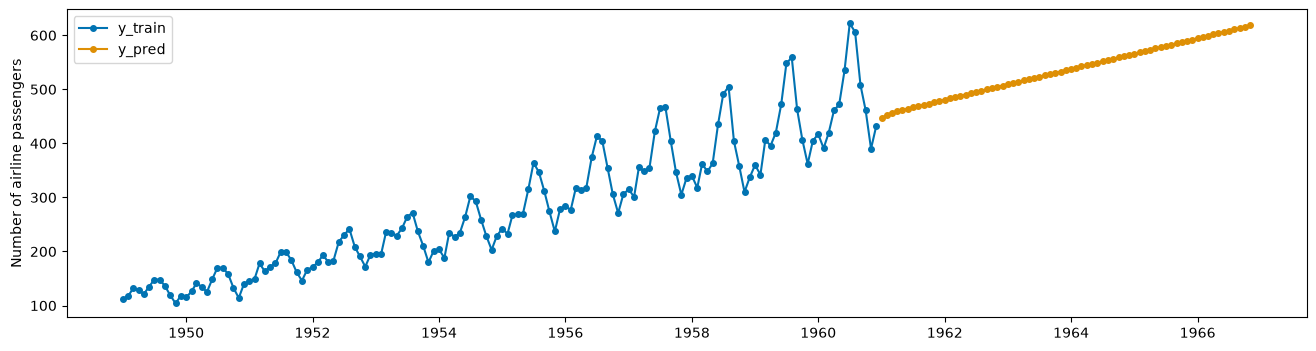

In [17]:
dates_range = list(range(1, 72))
fh_long = ForecastingHorizon(values=dates_range, is_relative=True)
forecaster.fit(y)
y_pred = forecaster.predict(fh_long)
plot_series(y, y_pred, labels=["y_train", "y_pred"])

### Why Do We Suck? Seasonality!

This data appears to have a strong seasonal pattern. We see lots of flights in the summer, then fewer in the winter. The stock arima isn't capturing this up and down each year, since we haven't set it up. We do get the overall trend, but not the up and down swings. We can attempt to add it with a seasonal term. 

The seasonal term is a tuple of 4 values, the first 3 are the same as the ARIMA model, and the last is the period of the seasonality. We can try a few different combinations to see what works best.

#### Setting the Shift

To do the further analysis, we need to set the seasonal period. In this case, we know that the data is monthly and has a yearly seasonality, so we set the period to 12. I'll set the dataset for this to be differenced by the period, and proceed. 

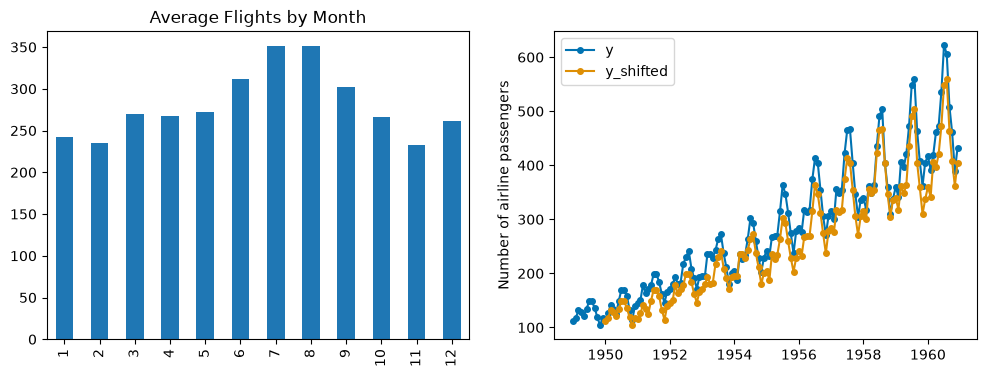

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
flights_by_month = y.groupby(y.index.month).mean()
flights_by_month.plot(kind="bar", title="Average Flights by Month", ax=axes[0])
# plot y shifted by 12

y_shifted = y.shift(12)
plot_series(y, y_shifted, labels=["y", "y_shifted"], ax=axes[1])
seasonal_period = 12

y_seas_diff = y.diff(seasonal_period).dropna()

#### Perform Seasonal ARIMA

We can start by finding the period, or how long the cycle of the seasonal pattern is. This can normally be done visually, with a dash of domain knowledge. Our scenarion will almost certainly be 12 months, since our data repeats year over year. We can also use the autocorrelation function to find the period, which will show a spike at the period of the seasonality.

#### Determine D

We can use the same process as before to determine the D term, or the number of differences needed to make the data stationary. We can use the ADF test again, and look for a p-value less than 0.05.

In [19]:
# Perform ADF test on the differenced series
seas_adf = adfuller(y_seas_diff)

print('ADF Statistic: %f' % seas_adf[0])
print('p-value: %f' % seas_adf[1])
seasonal_d = 1
y_seas_diff = y_seas_diff.diff().dropna()

ADF Statistic: -3.383021
p-value: 0.011551


/tmp/ipykernel_46451/2653469032.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  seas_adf = adfuller(y_seas_diff)


(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Number of airline passengers'>)

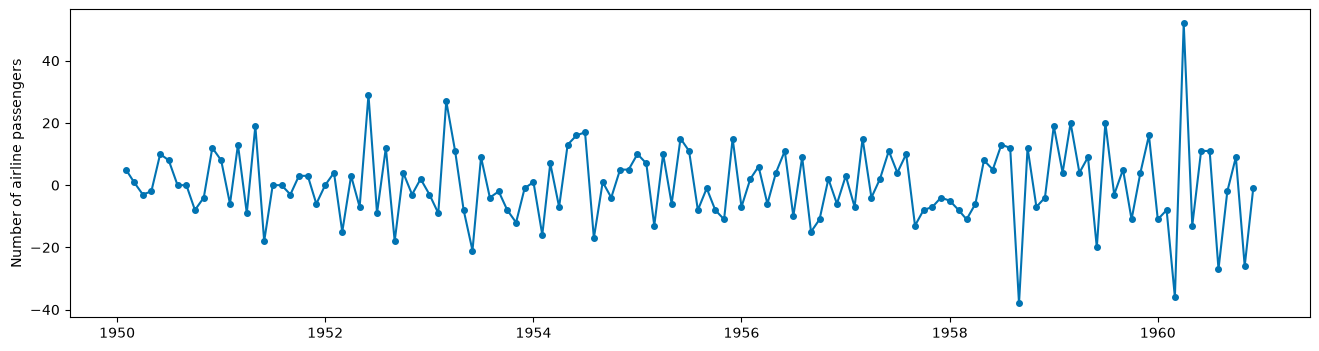

In [20]:
plot_series(y_seas_diff)

#### P and Q

A single differencing looks ok-ish. We can now look at the ACF and PACF plots to determine the p and q terms. We can look for a sharp cut off in the PACF for p, and a sharp cut off in the ACF for q.

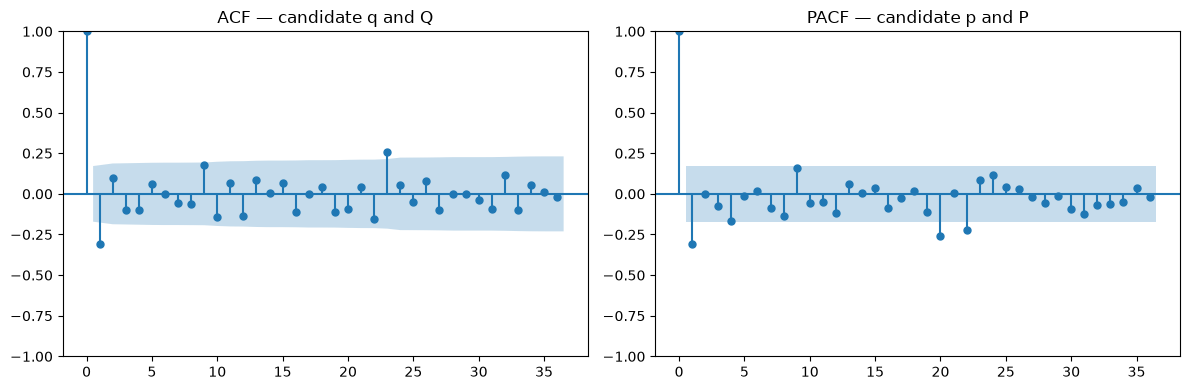

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(y_seas_diff, lags=36, ax=axes[0])
axes[0].set_title("ACF — candidate q and Q")

plot_pacf(y_seas_diff, lags=36, ax=axes[1])
axes[1].set_title("PACF — candidate p and P")

plt.tight_layout()
plt.show()

In [22]:
seasonal_p = 1
seasonal_q = 1

### Add Seasonality to Model

We can try to recreate the above model with seasonality added. 

np.float64(0.04341765443930643)

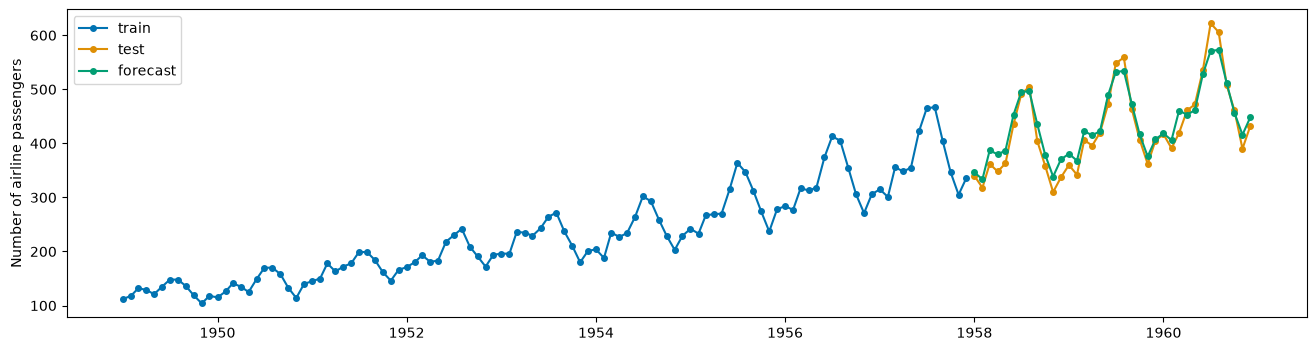

In [23]:
forecaster = ARIMA(order=(0, 1, 1), seasonal_order=(seasonal_p, seasonal_d, seasonal_q, seasonal_period), suppress_warnings=True)
forecaster.fit(y_train)
y_pred = forecaster.predict(fh)

plot_series(y_train, y_test, y_pred, labels=["train", "test", "forecast"])
mean_absolute_percentage_error(y_test, y_pred)

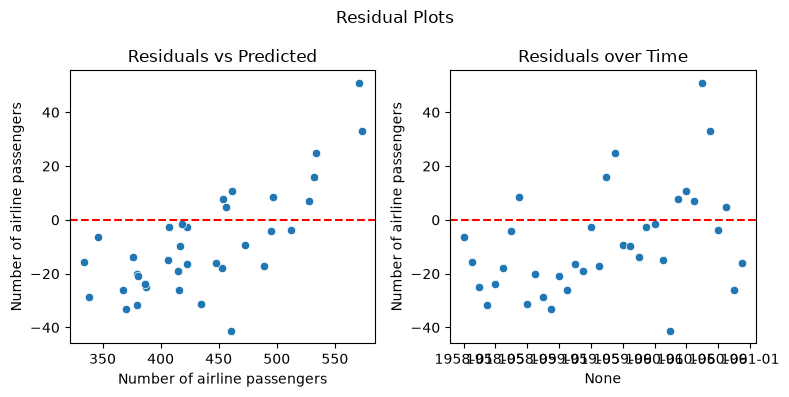

In [24]:
residual_plot(y_test, y_pred)

### Results - How Cool Are We?

## AutoARIMA

Going through all that work to find ARIMA terms seems suboptimal, and it is. We can use AutoARIMA to do a grid-search-ish process to find the ARIMA values for us. We supply the sp=12 for the seasonality pattern. Try without it, or with something different and observe. In practice, this is probably a better overall approch unless we are really trying to tailor a model in a very customized way. For us, we are happy with this, skipping the work we did above. 

In [25]:
from sktime.forecasting.arima import AutoARIMA

0.04148971436670213
{'ar.L1': np.float64(-0.24111777692520195), 'sigma2': np.float64(92.74986063943679), 'order': (1, 1, 0), 'seasonal_order': (0, 1, 0, 12), 'aic': np.float64(704.0011679025167), 'aicc': np.float64(704.1316026851255), 'bic': np.float64(709.1089216857179), 'hqic': np.float64(706.0650836395182)}


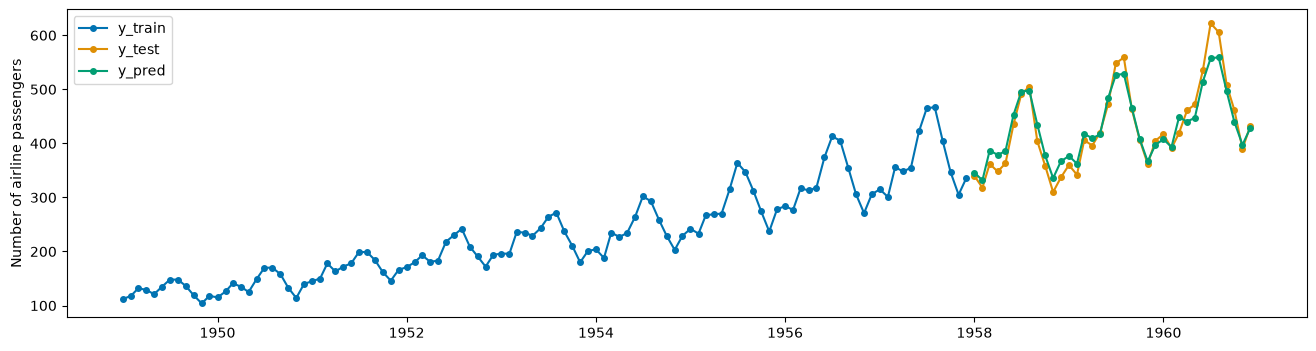

In [26]:
forecaster = AutoARIMA(sp=12, suppress_warnings=True)

forecaster.fit(y_train)
y_pred = forecaster.predict(fh)
plot_series(y_train, y_test, y_pred, labels=["y_train", "y_test", "y_pred"])
print(mean_absolute_percentage_error(y_test, y_pred))
print(forecaster.get_fitted_params())

#### With a Transformation

The passenger counts grow over time, and the seasonal swings grow with them. A Box-Cox transformation can reduce this level-dependent variance, which may help a forecasting model. It does not remove trend or seasonality. The plots below compare the training series before and after the transformation, including their 12-month rolling standard deviations.

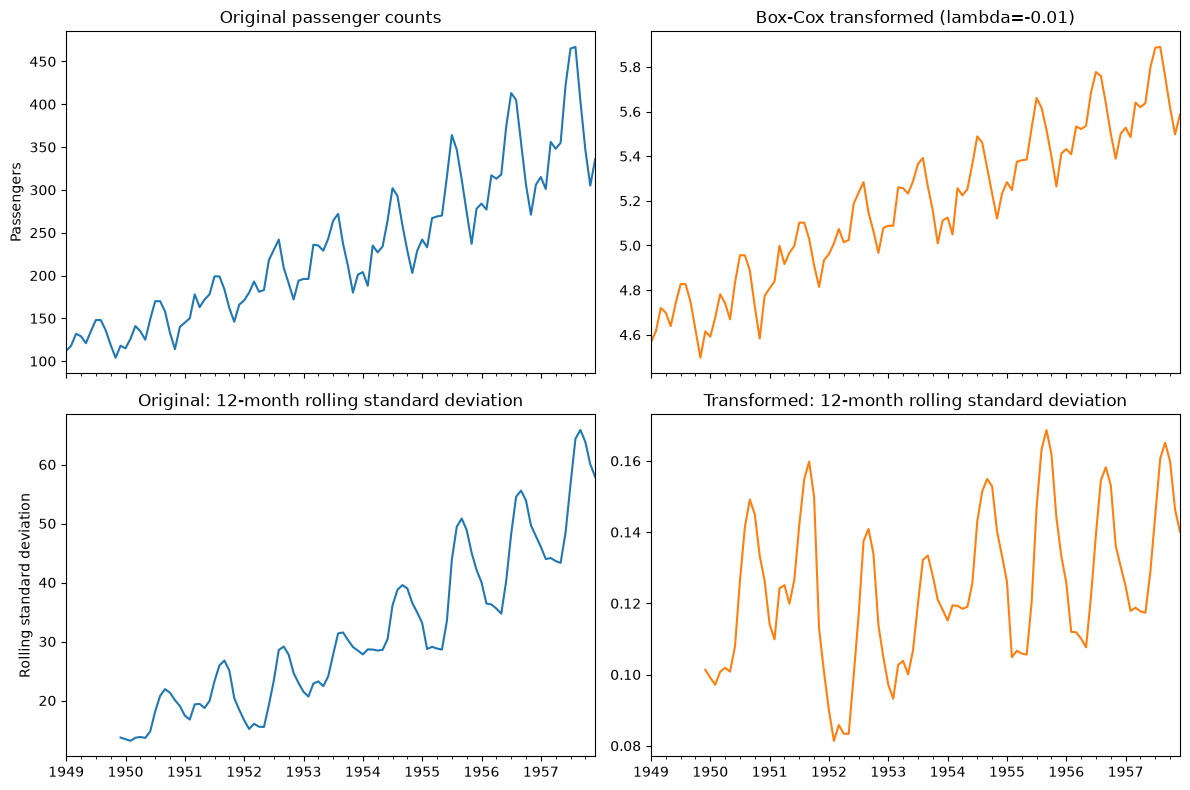

In [27]:
boxcox_method = "mle"  
from sktime.transformations.boxcox import BoxCoxTransformer

# Fit on training data only, so the held-out test period does not affect lambda.
boxcox_transformer = BoxCoxTransformer(method=boxcox_method)
y_train_boxcox = boxcox_transformer.fit_transform(y_train)

window = 12
fig, ax = plt.subplots(2, 2, figsize=(12, 8), sharex="col")

y_train.plot(ax=ax[0, 0], color="tab:blue")
ax[0, 0].set_title("Original passenger counts")
ax[0, 0].set_ylabel("Passengers")

y_train_boxcox.plot(ax=ax[0, 1], color="tab:orange")
ax[0, 1].set_title(
    f"Box-Cox transformed (lambda={boxcox_transformer.lambda_:.2f})"
)

# Compare how each series' rolling variability changes as its level grows.
y_train.rolling(window=window, min_periods=window).std().plot(
    ax=ax[1, 0], color="tab:blue"
)
ax[1, 0].set_title("Original: 12-month rolling standard deviation")
ax[1, 0].set_ylabel("Rolling standard deviation")

y_train_boxcox.rolling(window=window, min_periods=window).std().plot(
    ax=ax[1, 1], color="tab:orange"
)
ax[1, 1].set_title("Transformed: 12-month rolling standard deviation")

fig.tight_layout()

0.1296905178468265


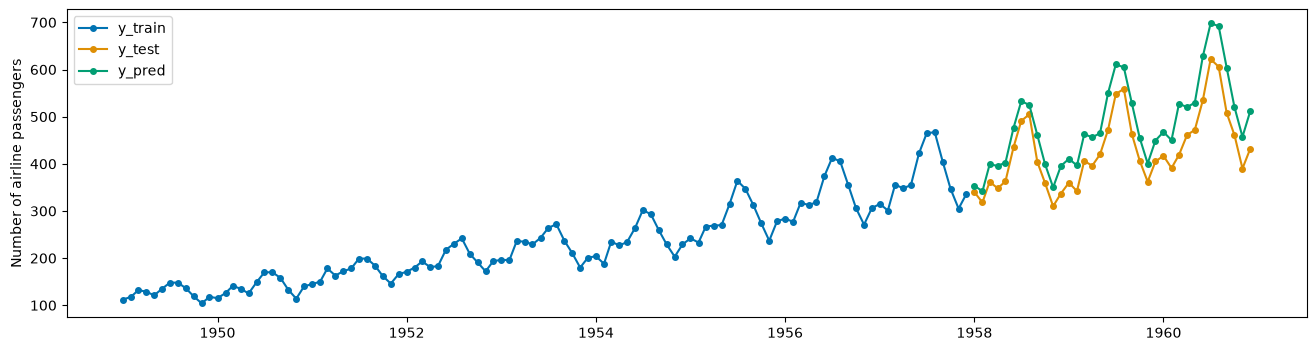

In [28]:
boxcox_forecaster = TransformedTargetForecaster([
    ("boxcox", BoxCoxTransformer(method=boxcox_method)),
    ("autoarima", AutoARIMA(sp=12, suppress_warnings=True)),
])

boxcox_forecaster.fit(y_train)
boxcox_pred = boxcox_forecaster.predict(fh)

plot_series(y_train, y_test, boxcox_pred,
            labels=["y_train", "y_test", "y_pred"])
print(mean_absolute_percentage_error(y_test, boxcox_pred))

Sadly, no improvement this time. Maybe there's some other transformer that will help...

## Simple Model Results

Above, all of the models are pretty similar, all of them generating pretty accurate predictions in our test data. This toy dataset is pretty easy to predict, the patterns in the data look quite uniform, so something like the simple exponential smoothing model is able to model it quite well. A pattern like this isn't uncommon for forecasting - we want to try models that are simple first, then look to make things more complex if we need to. Remember that we're literally making predictions in the future, which obviously has a lot of uncertainty - sometimes ingoring all of the other data that we may think is important and just using a simple model that extends the pattern is the best approach.

## Automated Tools and Pipelines

Since sktime is structured like sklearn, we can incorporate things into standard functionality like pipelines. The sktime library provides a TransformedTargetForecaster that we can use as a pipeline - the reason for this difference is because the time series data is the target data, not the feature set like a normal pipeline. 

There are also a few other automated tools that we won't explore in detail, but are clearly named and explained in the documentation:
<ul>
<li> Detrender - remove trends from time series. 
<li> Deseasonalizer - remove seasonality from time series. 
</ul>

Both transform the time series data to remove the non-stationary bits. 

In [ ]:
from sktime.forecasting.trend import PolynomialTrendForecaster
from sktime.transformations.series.detrend import Detrender
from sktime.transformations.series.detrend import Deseasonalizer

np.float64(0.05712665963190679)

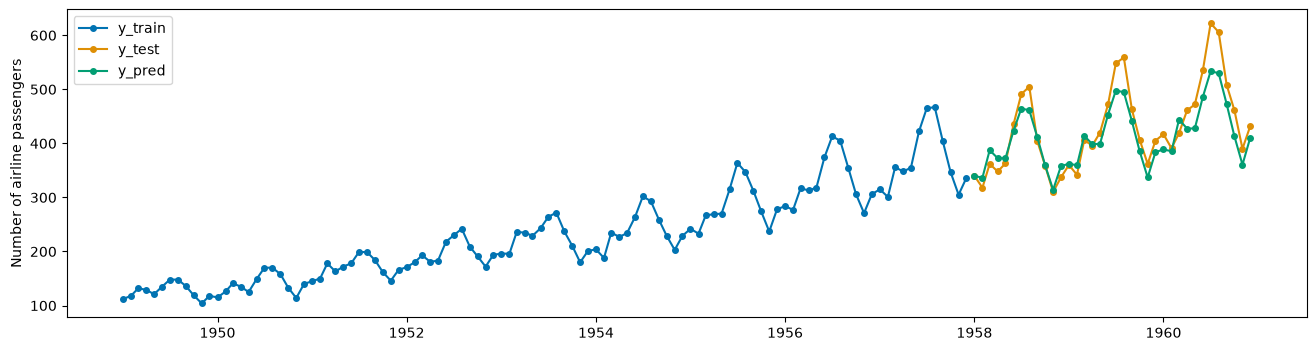

In [30]:
forecaster = TransformedTargetForecaster(
    [
        ("deseasonalize", Deseasonalizer(model="multiplicative", sp=12)),
        ("detrend", Detrender(forecaster=PolynomialTrendForecaster(degree=1))),
        ("forecast", AutoARIMA()),
    ])

forecaster.fit(y_train)
y_pred = forecaster.predict(fh)
plot_series(y_train, y_test, y_pred, labels=["y_train", "y_test", "y_pred"])
mean_absolute_percentage_error(y_test, y_pred)

## FaceBook Prophet, Part 1

One different thing that we can do with sktime is that we can import a pre-trained model and use it - in this case something offered by Facebook called Prophet. This package is a more sophisticated model for time series predictions created by Facebook. We can look to the documentation for details. We can use it's "smarts", supply some basic parameters based on our data, and get a model that is ready to go.

<b>Note:</b> here we are using a sklearn wrapper on the the full FB Prophet package, which makes it simple to set things like the seasonality. Later when we add multiple regressors, we can use the normal Prophet package.

In [31]:
# Load the SKTime Prophet 
from sktime.forecasting.fbprophet import Prophet

17:31:09 - cmdstanpy - INFO - Chain [1] start processing
17:31:09 - cmdstanpy - INFO - Chain [1] done processing


np.float64(0.07235115903871418)

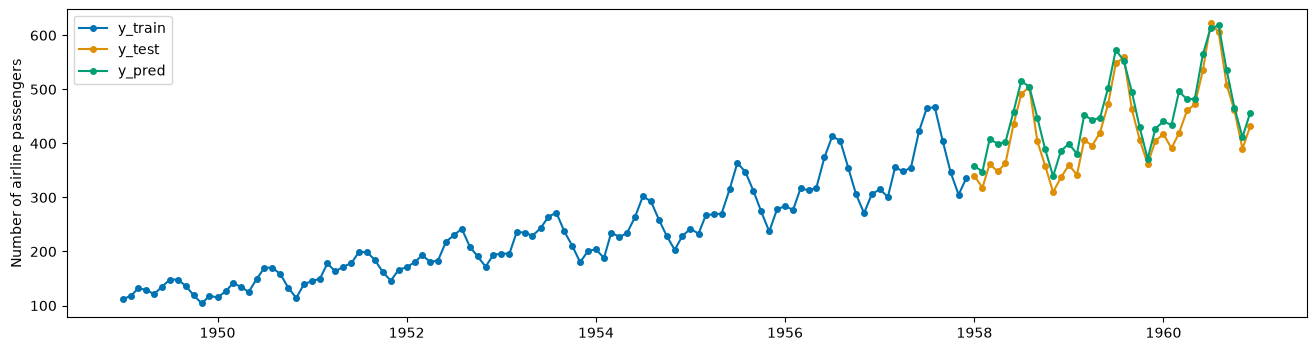

In [32]:
# Convert index to pd.DatetimeIndex
z = y.copy()
z = z.to_timestamp(freq="M")
z_train, z_test = temporal_train_test_split(z, test_size=36)


forecaster = Prophet(
    seasonality_mode="multiplicative",
    n_changepoints=int(len(y_train) / 12),
    add_country_holidays={"country_name": "Canada"},
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
)

forecaster.fit(z_train)
y_pred = forecaster.predict(fh.to_relative(cutoff=y_train.index[-1]))
y_pred.index = y_test.index

plot_series(y_train, y_test, y_pred, labels=["y_train", "y_test", "y_pred"])
mean_absolute_percentage_error(y_test, y_pred)

## Exercise - Predict Shampoo Sales in the Future

We'll load some data on shampoo sales, and try to predict the future. Try a few ways. 

36


(<Figure size 1600x400 with 1 Axes>, <Axes: ylabel='Number of shampoo sales'>)

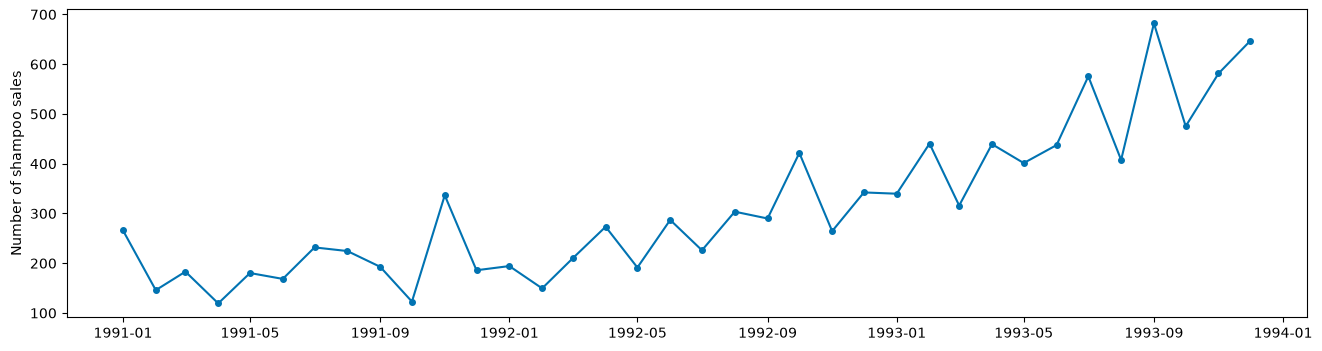

In [33]:
from sktime.datasets import load_shampoo_sales
sh = load_shampoo_sales()
print(len(sh))
plot_series(sh)

#### Split

#### Exponential Smoothing

#### ARIMA

#### AutoARIMA

#### Predict Into Future

## Multiple Regressors and Facebook Prophet, Part 2

We can try to predict some stock prices, and use the full Prophet model to do so. One thing that we need to do a little differently is to prepare the data especially for Prophet. We are expected to have a dataframe with:
<ul>
<li> <b>ds</b> - the date column is labeled "ds".
<li> <b>y</b> - the target column is labeled "y".
<li> <b>Other Regressor</b> - any other columns that we want to use as regressors. These have no name rules. 
</ul>

We'll also use the Yahoo finance module to download some data on stock prices. 

Prophet has a bunch more options that we can configure, the documentation is https://facebook.github.io/prophet/docs/quick_start.html#python-api In general, it offers a relatively easy way to implement many of the common things that we'd want to concern ourselves with when doing forecasting. We can add cross validation, holidays, shock changes (such as COVID), etc... 

#### Additional Regressors

Adding additional regressors is pretty easy. We just need to make sure that the data is in the right format, and that we have the right columns. <b>One key thing is that we need to be able to know the regressor data for where the forecasts are taking place, as it is an input to the model.</b> This example fudges that a little bit, in a real application we can only use the things that we <b>do know</b> at the moment the prediction into the future is made.  

<b>Note:</b> in these examples we aren't *really* trying to select great features, we are just illustrating the tools. If we were doing this for real, we'd need to increase our domain knowledge on the topic a bit, and do some more feature engineering to determine useful features. We will worry more about that during the machine learning section. 

In [ ]:
from prophet import Prophet as fbProphet

In [43]:
#stock = yf.Ticker("C")
#stock = yf.Ticker("NFLX")
stock = yf.Ticker("MSFT")
startd = "2022-06-01"
endd = "2025-01-31"
tests = 60

hist = stock.history(start=startd, end=endd)

hist = hist.reset_index()
hist.rename(columns={"Date": "ds", "Close": "y"}, inplace=True)
hist.head()


/tmp/ipykernel_46451/3392867288.py:11: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  hist.rename(columns={"Date": "ds", "Close": "y"}, inplace=True)


,ds,Open,High,Low,y,Volume,Dividends,Stock Splits
0,2022-06-01 00:00:00-04:00,265.252417,267.652402,260.278931,262.572906,25292200,0.0,0.0
1,2022-06-02 00:00:00-04:00,254.891007,264.722292,252.144019,264.654816,44008200,0.0,0.0
2,2022-06-03 00:00:00-04:00,260.539139,263.565652,258.707824,260.259613,28059000,0.0,0.0
3,2022-06-06 00:00:00-04:00,262.225905,264.269269,257.560859,259.035553,22400300,0.0,0.0
4,2022-06-07 00:00:00-04:00,257.001858,263.257257,256.327149,262.650024,22860700,0.0,0.0


In [44]:
stock

yfinance.Ticker object <MSFT>

<Axes: xlabel='ds', ylabel='y'>

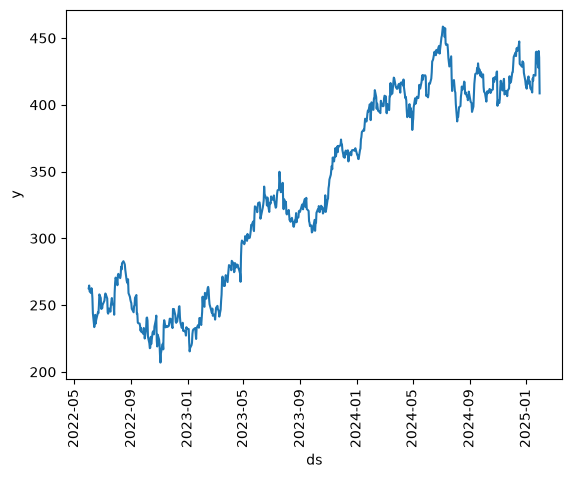

In [45]:
plt.xticks(rotation=90)
sns.lineplot(x=hist.ds, y=hist["y"])

##### Make Prophet Model 

We'll just split the dataframe as a whole, since Prophet expects the dataframe format. It knows what it is doing with each column due to the naming standard for "ds" and "y", the additional regressors are specified as we add them. Just as with a normal dataset for a regression model, adding regressors basically just adds more X columns to the feature set. 

17:31:20 - cmdstanpy - INFO - Chain [1] start processing
17:31:20 - cmdstanpy - INFO - Chain [1] done processing


np.float64(0.06477024299430831)

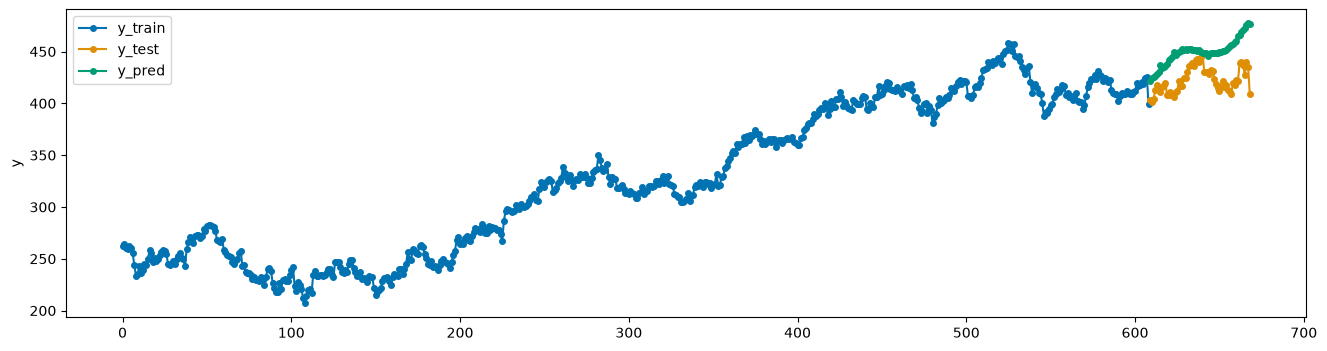

In [46]:
# Convert index to pd.DatetimeIndex

hist["ds"] = hist["ds"].dt.tz_localize(None)
hist["ds"] = pd.to_datetime(hist["ds"], errors='coerce')
train, test = temporal_train_test_split(hist, test_size=tests)

stockP = fbProphet()

stockP.add_country_holidays(country_name="US")
#stockP.add_seasonality(name="weekly", fourier_order=10, period=4)

stockP.add_regressor("Volume")
stockP.add_regressor("Dividends")
stockP.add_regressor("Stock Splits")

stockP.fit(train)
preds = stockP.predict(test)
preds.index = test.index
#preds

plot_series(train["y"], test["y"], preds["yhat"], labels=["y_train", "y_test", "y_pred"])
mean_absolute_percentage_error(test["y"], preds["yhat"])

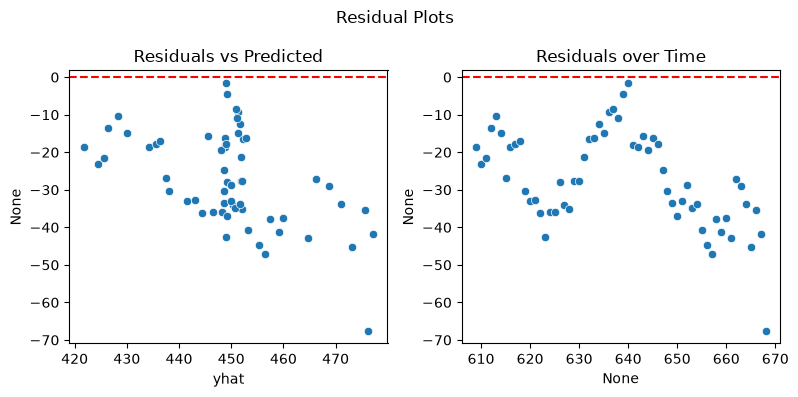

In [47]:
residual_plot(test["y"], preds["yhat"])

We can also extract the components of the time series model, and plot them individually.

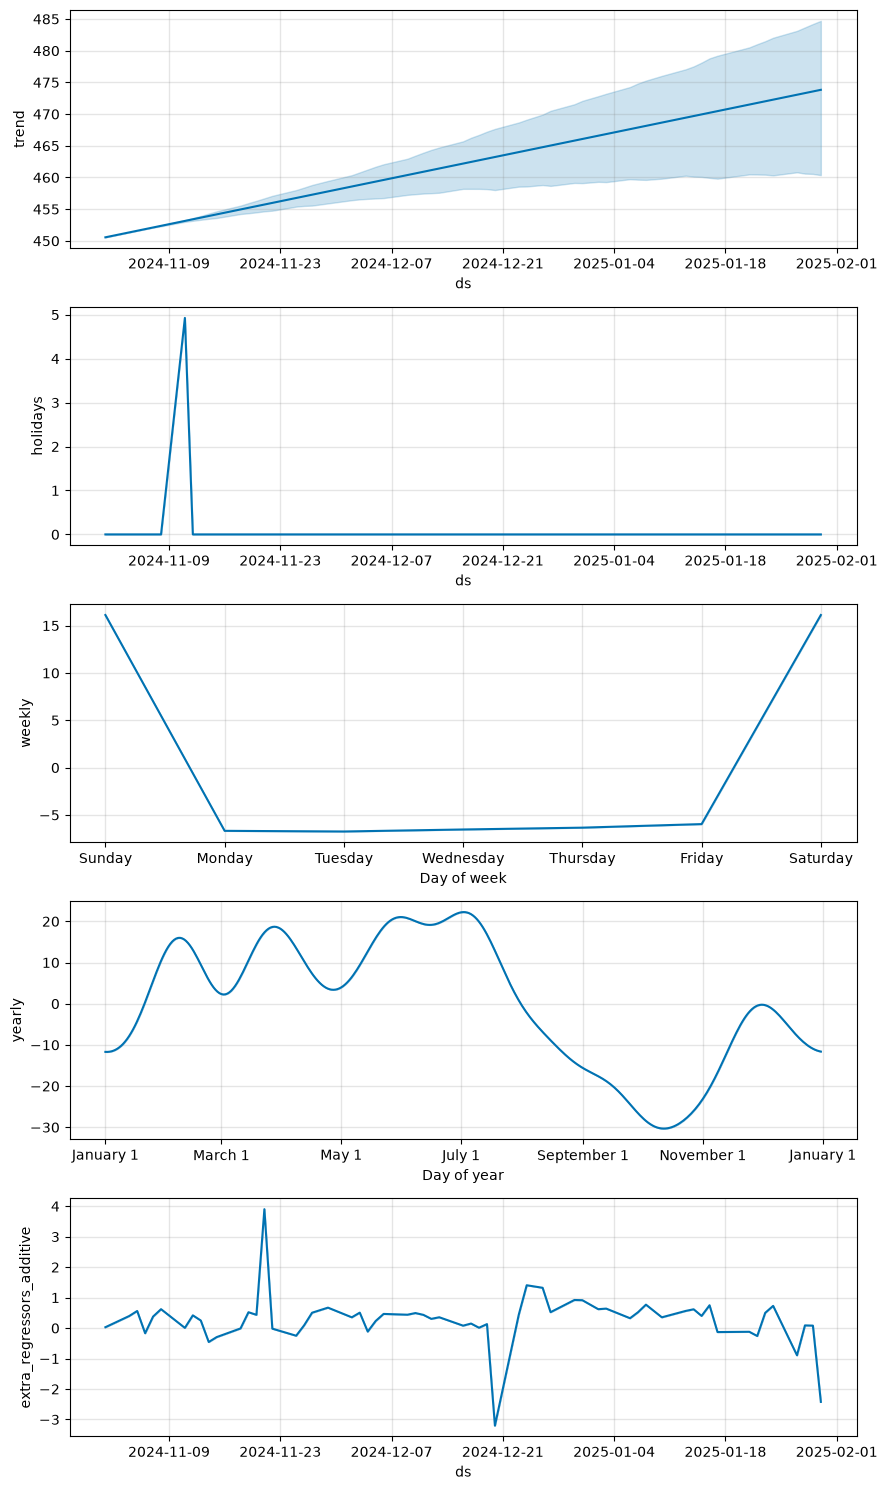

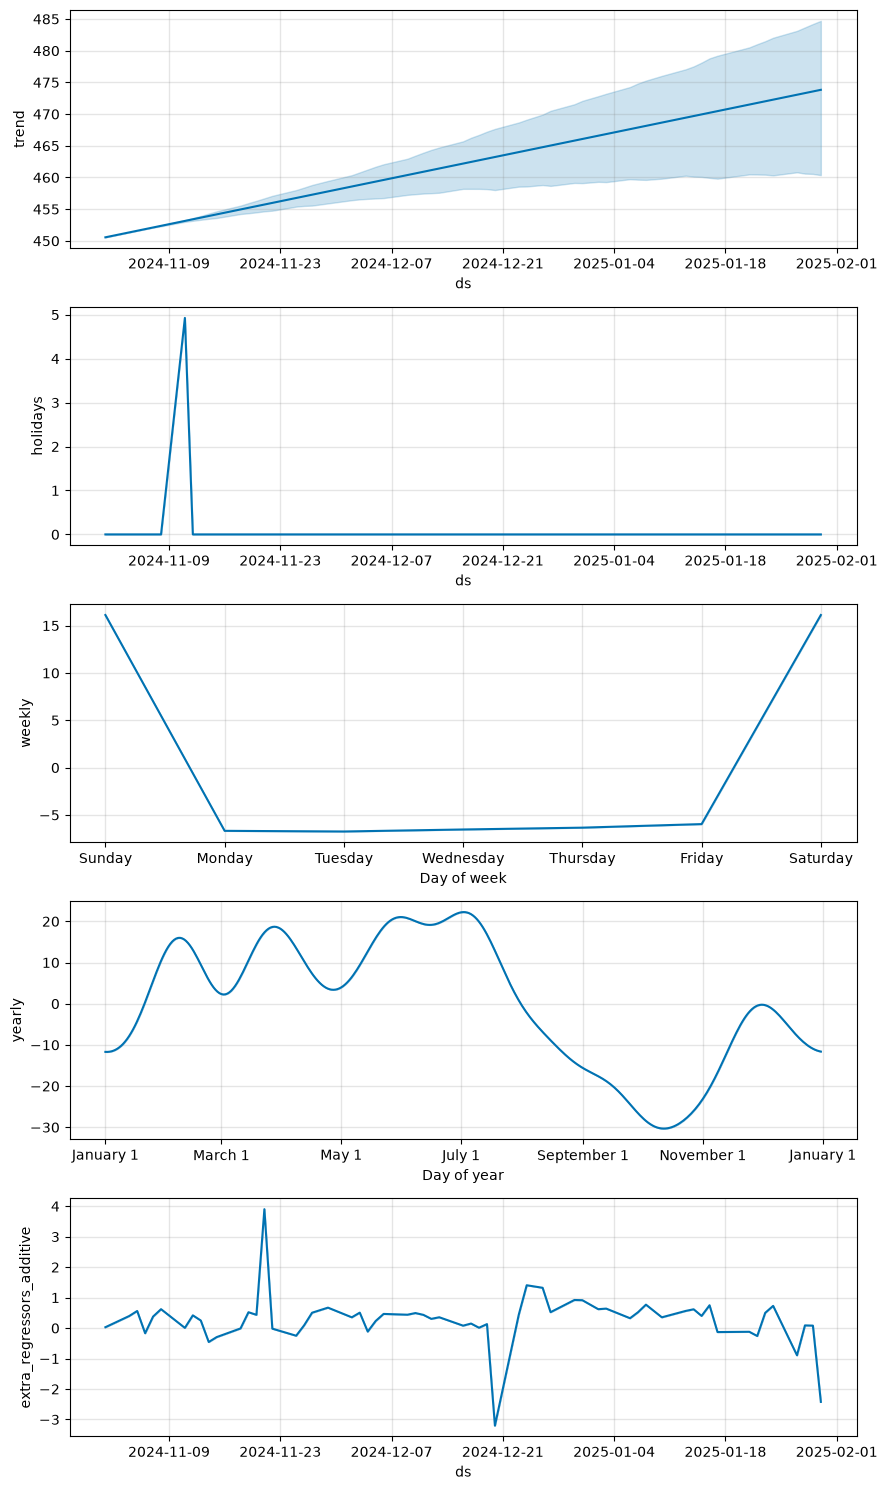

In [48]:
stockP.plot_components(preds)

### Future and Regressors

We can also use the Prophet model to plot projections into the future. One key factor that will impact us here is that <b>we don't have the future data for the regressors that we've added to the model</b>. To build forecasts looking out into the future, we need those values. This is one common limitation of adding regressors to a time series model. We can take one of, or a combination of, a couple of approaches:
<ul>
<li> Construct a forecast for the regressors, and use that to predict the future regressor values. This could be a Prophet model, exponential smoothing, or something else. 
<li> Recreate regressors to be a function of time, and use that to predict the future regressor values.
<li> Carry on the last known value of the regressor.
<li> Build only regressors that are backwards looking, such as the average of the last 5 days instead of the current value. 
</ul>

Obviously this requires some knowledge of the data and the problem, without those we are definitely going to be introducing some substantial uncertainty into our model. What these regressors are and how they are generated will have a distinct impact on the projections that we make. Creating a prediction for a feature to a predictive model is similar in spirit to what we did in imputation, but this tends to be much more substantial. 

#### Regressor Free Model and Sesaonality Proejctions

We'll make a regressor-free example here, and generate some forecasts. We'll also add in seasonality. For seasonality we need to specify a few things - the name and period just define the period of the seasonality. The Fourier order is the number of terms in the Fourier series that we use to model the seasonality, which is beyond our scope to care about in detail. It is a parameter that we can tune, the larger the value, the more quickly the seasonality can change. Larger values are also more prone to overfitting, as they are increasing the complexity of the model. 

In [52]:
stock2 = fbProphet(weekly_seasonality=True)
stock2.add_country_holidays(country_name="US")
stock2.add_seasonality(name="weekly", fourier_order=10, period=5)
stock2.fit(hist)

17:33:10 - cmdstanpy - INFO - Chain [1] start processing
17:33:10 - cmdstanpy - INFO - Chain [1] done processing


#### Make Dataframe

We can project into the future and plot it. Here I'm going to specify a year, but that isn't straightforward. Since our data is weekday only, we can tell Prophet to generate a dataframe with only weekdays by passing the parameter freq='B', and we can ask for a year of data by passing the parameter periods=252, which is a value I googled for "weekdays in a year". 

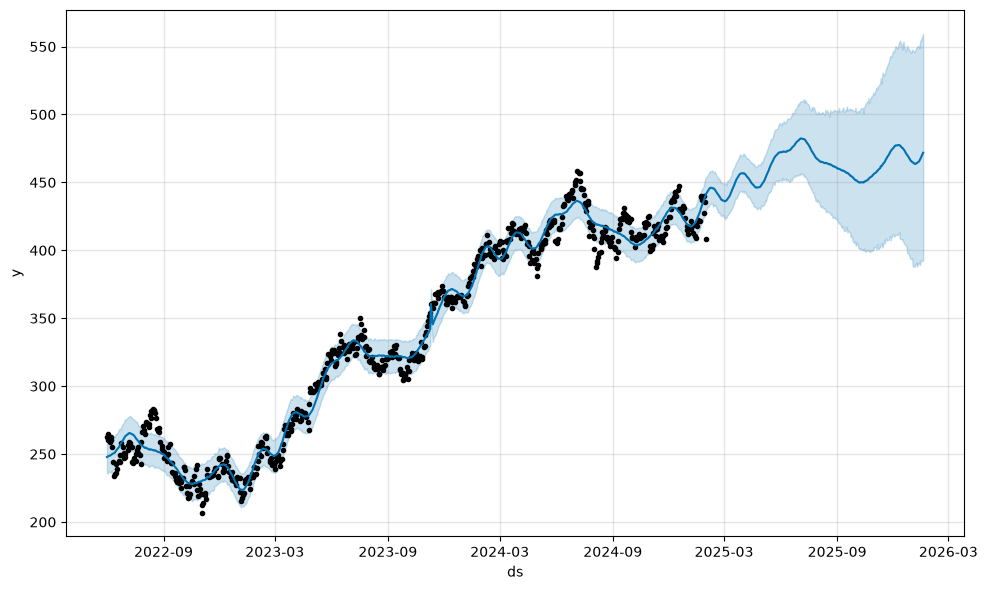

In [53]:
future = stock2.make_future_dataframe(periods=252, freq="B")
forecast = stock2.predict(future)
fig = stock2.plot(forecast)

We can also extract the parts of the time series. 

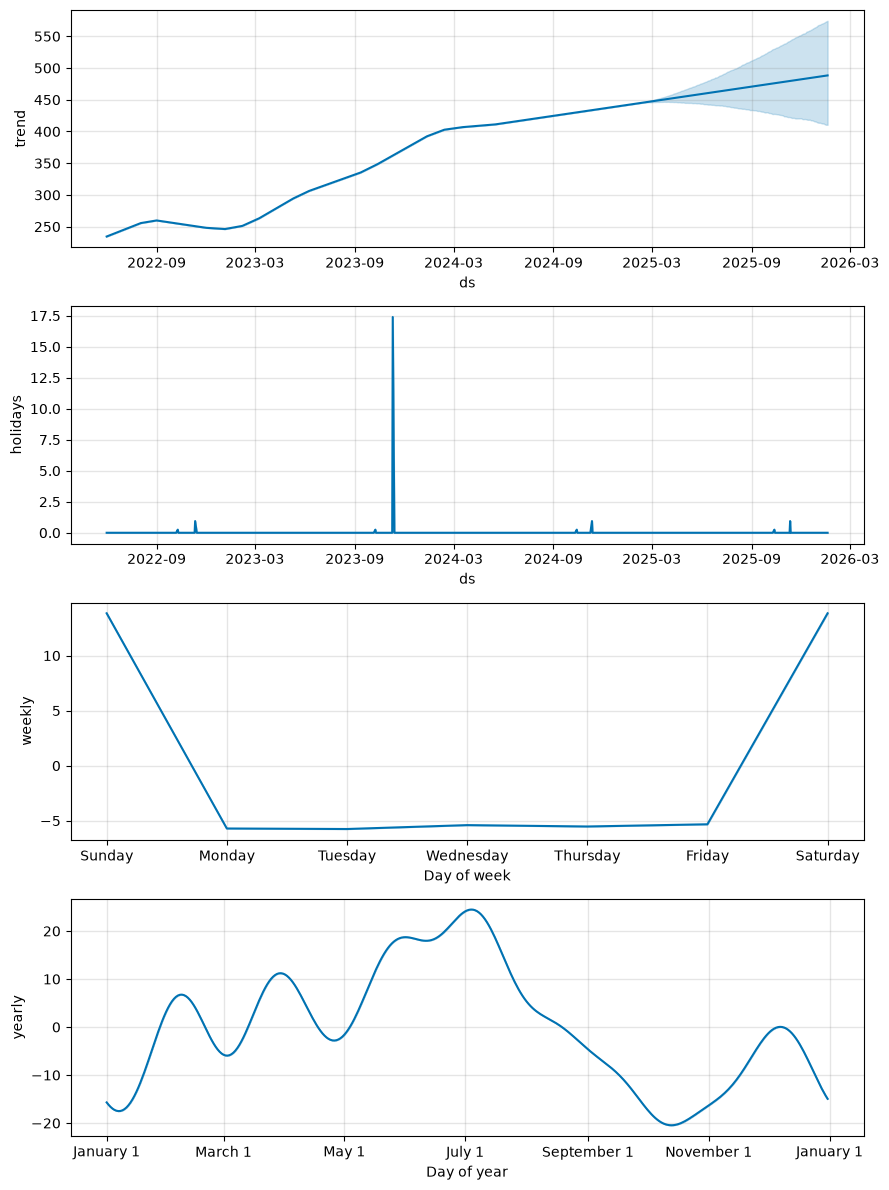

In [54]:
fig2 = stock2.plot_components(forecast)

### Results

Maybe ok, maybe not. One thing to think of in time series data is the lag between when things happen. For example, dividends and stock splits both tend to increase the price of a stock, however that increase happens after the event is announced, not when it actually happens. If you've ever heard the term "priced in", that is what is they are refering to, the price has altered to reflect the event. In this case, we might want to transform the data for splits and dividends to be a "days since" value, so that the model can learn that the price will increase in the future. Will this work? Maybe, we are basically attempting to construct something that models real stock prices, which are complex. We don't have a definitive answer on what to do with the data, it is a trial and error process. 

Prophet also has a lot more options and features that you can explore if needed. In particular, it has a lot of options that are likely to be relevant for businesses, like the ability to custom define holidays and points in time where change can be expected, such as a new product launch, a large sale, or an explosion in news. All of these things can be constructed into other models, but Prophet makes stuff like that easy. 

## Time Series Wrap Up

Time series forecasting is a complex topic, and we've only scratched the surface. We've covered some of the basics of making forecasts, but there are more options and techniques out there. In particular, the construction of the datasets is both critical and flexible, and generally depends on domain knowledge. How we construct the data, and what we understand it to represent, will have a large impact on the results. For example, a stock price can be a price that we are predicting, as we did above; a stock price could also be the end result of a series of increases/decreases, if we were to construct a model that predicts the daily delta. For the stock example here, we could do something like transform the "Volume" feature into something like "Yesterday's Volume", or "Moving Avg of Recent Volume", so it can be used as a regressor that we'd know ahead of time. Is this a good idea? We have no clue, people making models like this to predict stock performance get paid a lot of money to figure out ways to manipulate data and create custom models that are a couple of fractions of a percent more accurate than what currently exists. As well, forecasting multiple time periods into the future is inherently more difficult and open ended, because all of our inputs have to come from the past. Even something like time of day has a lot of complexity - do we care about the specific minute, the hour, morning/afternoon/evening, etc? We need to build an understanding of the scenario to reasonably construct models to forecast it. Time series forecasting requires a somewhat different, and I'd argue more extensive, approach to preparing a dataset that captures the variance that we are trying to predict. 

All in all, we can build upon what's here to approach time series challenges, but we probably shouldn't assume that any of the above approaches will be a perfect fit for real life problems. We'd want to expand on the tools here if we are going to dig more into forecasting. In particular, there are families of neural network models that are well suited to sequential data like these time series, such as recurrent neural networks and in the past few years, transformers. These models have undergone rapid recent improvements as applications like language generation and translation are laregly a sequential problem. 